In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from   matplotlib import colors
import matplotlib.patches as mpatches

from scipy.spatial import KDTree
from scipy.stats import mannwhitneyu, kruskal

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from pandas.api.types import CategoricalDtype
import seaborn as sns
import os

In [2]:
#### Set plotting parameters
matplotlib.rcParams.update({
    "font.family":        "Liberation Sans",
    "pdf.fonttype":       42,   # TrueType → keeps glyphs grouped in Illustrator
    "ps.fonttype":        42,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.25,
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.minor.width":  0.5,
    "ytick.minor.width":  0.5,
    "xtick.major.size":   3.5,
    "ytick.major.size":   3.5,
    "axes.labelsize":     6,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6,
    "legend.fontsize":    5,
    "axes.titlesize":     7,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.transparent": False,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
})

### inches to points conversion
MM = 1 / 25.4
NATURE_2COL_MM = 183                 # Nature double-column width


___
### Load RNA object

In [3]:
# ── File paths — edit these ───────────────────────────────────────────────────
ADATA_PATH  = 'seqFISH_discovery_cohort.h5ad'   # AnnData object

OUT_DIR = 'figures/'
os.makedirs(OUT_DIR, exist_ok=True)

print('Paths configured.')

Paths configured.


In [4]:
# ── Load adata and merge all metadata into adata.obs ──────────────────────
adata = ad.read_h5ad(ADATA_PATH)

total_samples = len(adata.obs['ROI'].unique())
total_patients= len(adata.obs['patient'].unique())
total_cells = adata.shape[0]
mean_counts = np.mean(np.sum(adata.layers['counts'].toarray(), axis=1))
sd_counts   = np.std(np.sum(adata.layers['counts'].toarray(), axis=1))
mean_genes  = np.mean(np.sum(adata.layers['counts'].toarray() > 0, axis=1))
sd_genes    = np.std(np.sum(adata.layers['counts'].toarray() > 0, axis=1))

print(adata.obs['state'].unique())
print(adata.obs['sample_group'].unique())

print(f'## {total_samples} total samples')
print(f'## {total_patients} patients')
print(f'## {total_cells} total cells')
print(f'{mean_counts} ( {sd_counts} ) mean counts per cell ')
print(f'{mean_genes} ( {sd_genes} ) mean unique genes per cell ')

['GBM', 'future MT', 'Transformed', 'future stable']
Categories (4, object): ['GBM', 'Transformed', 'future MT', 'future stable']
['GBM', 'future MT', 'Transformed', 'future stable | Rec', 'future stable | Init', 'Gliosarcoma']
Categories (6, object): ['GBM', 'Gliosarcoma', 'Transformed', 'future MT', 'future stable | Init', 'future stable | Rec']
## 42 total samples
## 23 patients
## 693013 total cells
839.2365112304688 ( 692.210205078125 ) mean counts per cell 
224.07219200794214 ( 104.22522339981906 ) mean unique genes per cell 


___
### Plot cell type compositions and spatial distributions

In [5]:
# ---- Nature-ish rcParams (embed fonts, small sizes, thin lines) ----
plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6, "axes.linewidth": 0.5,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2,
    "savefig.dpi": 400,
})


# ----------------------------------------------------------------------
# small helpers
# ----------------------------------------------------------------------
def _bh_fdr(pvals):
    """Benjamini-Hochberg FDR; ignores NaN, returns q aligned to input order."""
    p = np.asarray(pvals, float)
    q = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    ps = p[ok]
    m = ps.size
    if m == 0:
        return q
    order  = np.argsort(ps)
    ranked = ps[order]
    qv = ranked * m / np.arange(1, m + 1)
    qv = np.minimum.accumulate(qv[::-1])[::-1]
    qv = np.clip(qv, 0, 1)
    out = np.empty(m); out[order] = qv
    q[ok] = out
    return q
 
 
def _stars(q):
    if not np.isfinite(q):
        return ""
    if q < 1e-3:
        return "***"
    if q < 1e-2:
        return "**"
    if q < 5e-2:
        return "*"
    return ""
 
 
def _omnibus(arrays, min_n):
    """
    Between-group difference test across ANY number of groups.
      - keeps only groups with >= min_n finite values
      - needs >= 2 such groups, else NaN
      - exactly 2 groups  -> two-sided Mann-Whitney (exact; matches 2-group results)
      - 3+ groups         -> Kruskal-Wallis (non-parametric omnibus)
    """
    arrs = []
    for a in arrays:
        a = np.asarray(a, float); a = a[np.isfinite(a)]
        if a.size >= min_n:
            arrs.append(a)
    if len(arrs) < 2:
        return np.nan
    if np.ptp(np.concatenate(arrs)) == 0:      # all identical -> no difference
        return 1.0
    try:
        if len(arrs) == 2:
            return mannwhitneyu(arrs[0], arrs[1], alternative="two-sided").pvalue
        return kruskal(*arrs).pvalue
    except ValueError:
        return np.nan
 
def _grp_n_mean_sd(vals):
    """n (finite samples), mean, sample-sd (ddof=1) for one group's values."""
    v = np.asarray(vals, float)
    v = v[np.isfinite(v)]
    n = int(v.size)
    if n == 0:
        return 0, np.nan, np.nan
    mean = float(v.mean())
    sd   = float(v.std(ddof=1)) if n >= 2 else np.nan   # ddof=1: sample sd
    return n, mean, sd


def _test_name(arrays, min_n):
    """Name of the between-group test _omnibus() would run for these arrays."""
    k = sum(1 for a in arrays if np.isfinite(np.asarray(a, float)).sum() >= min_n)
    if k < 2:
        return "insufficient groups"
    return "Mann-Whitney U (two-sided)" if k == 2 else "Kruskal-Wallis"
    
def _box_strip(ax, values_per_pos, positions, colors, box_w=0.28,
               ptsize=5, jitter=0.06, rng=None):
    """Draw box + jittered strip for each position."""
    rng = rng if rng is not None else np.random.default_rng(0)
    for vals, pos, col in zip(values_per_pos, positions, colors):
        vals = np.asarray(vals, float); vals = vals[np.isfinite(vals)]
        if vals.size == 0:
            continue
        if vals.size >= 2:
            bp = ax.boxplot([vals], positions=[pos], widths=box_w,
                            patch_artist=True, showfliers=False,
                            manage_ticks=False,
                            medianprops=dict(color="black", lw=0.7),
                            boxprops=dict(lw=0.5),
                            whiskerprops=dict(lw=0.5),
                            capprops=dict(lw=0.5))
            for bx in bp["boxes"]:
                bx.set_facecolor(col); bx.set_alpha(0.30); bx.set_edgecolor(col)
        jit = (rng.random(vals.size) - 0.5) * 2 * jitter
        ax.scatter(pos + jit, vals, s=ptsize, color=col,
                   edgecolor="white", linewidth=0.25, zorder=3, alpha=0.9)
 
 

def plot_coloc_panel(coloc_df, group_colors, group_order, celltypes, out_dir,
                     celltype_order=None, radius=None, alpha=0.05,
                     group_short=None, min_valid=3, heatmap_agg="median",
                     fig_width_mm=NATURE_2COL_MM, ab_layout="stacked",
                     frac_spread=0.5, base_id_col="base_id", base_id_map=None):
    """
    Nature two-column co-localisation figure.

      a) Cell-type fraction per sample (box + strip), all groups dodged side by
         side, cell types ordered by overall mean fraction (largest first).
         Cell types differing between groups are starred.
      b) Per-group log2(observed/expected) co-localisation heatmaps (lower
         triangle), one per group. Pairs differing between groups (test on
         per-sample log2OE, BH-FDR across all pairs) are starred in every heatmap.
      c) For every significantly-different pair, the per-sample log2OE
         distribution split by group (box + strip). Omitted if none are
         significant.

    All three panels aggregate to the biological sample (base_id): fractions and
    log2OE are computed per ROI ("sample") and then averaged within each base_id,
    so a sample contributing several ROIs counts once, not many times. Supply the
    mapping via base_id_map={ROI: base_id} OR a base_id column already present in
    coloc_df (named by base_id_col); if neither is given, each ROI is treated as
    its own sample.

    Between-group testing works for ANY number of groups: exactly 2 groups use a
    two-sided Mann-Whitney; 3+ groups use Kruskal-Wallis. BH-FDR is applied across
    cell types (panel a) and across pairs (panel b).

    group_colors : {group_name: hex}. group_order : [g1, g2, ...]  (user input,
    any length >= 2). Only the groups listed in group_order are drawn and tested.

    ab_layout : "stacked" (default) puts the fraction panel and the heatmaps in
    separate rows; "row" places them side by side in a single row (fractions |
    heatmaps | colorbar), with panel c beneath spanning the full width.
    """
    group_short = group_short or {}
    rng = np.random.default_rng(0)

    # heatmap cell-type order (independent of the frequency-sorted fraction panel)
    if celltype_order:
        present  = set(celltypes)
        ordered  = [ct for ct in celltype_order if ct in present]
        leftover = [ct for ct in celltypes if ct not in ordered]
        heat_cts = ordered + leftover
    else:
        heat_cts = list(celltypes)
    ct_idx = {ct: i for i, ct in enumerate(heat_cts)}
    n_ct   = len(heat_cts)

    ng     = len(group_order)
    colors = [group_colors[g] for g in group_order]

    # ---------------------------------------------------------------
    # attach base_id (biological sample) to every ROI, then build a
    # base-level frame: one row per (base_id, group, pair) holding the
    # mean log2OE across that sample's ROIs. Panels a/b/c all aggregate
    # to base_id, so a sample with many ROIs counts once, not many times.
    # ---------------------------------------------------------------
    coloc_df = coloc_df.copy()
    if base_id_map is not None:
        coloc_df["base_id"] = coloc_df["sample"].map(base_id_map)
        if coloc_df["base_id"].isna().any():
            missing = coloc_df.loc[coloc_df["base_id"].isna(), "sample"].unique()
            raise ValueError(f"base_id_map missing {len(missing)} ROI(s): {missing[:5]}")
    elif base_id_col in coloc_df.columns:
        coloc_df["base_id"] = coloc_df[base_id_col]
    else:
        coloc_df["base_id"] = coloc_df["sample"]        # fallback: 1 ROI == 1 sample

    # per-base_id mean log2OE (mean skips undefined/NaN ROIs)
    coloc_base = (coloc_df
                  .groupby(["base_id", "sample_group", "typeA", "typeB"],
                           as_index=False)["log2OE"].mean())

    # ---------------------------------------------------------------
    # (a) cell-type fractions from the diagonal (typeA == typeB) rows.
    #     Fraction is computed per ROI, then averaged within each base_id
    #     so every biological sample contributes one point per cell type.
    # ---------------------------------------------------------------
    diag = coloc_df[coloc_df["typeA"] == coloc_df["typeB"]].copy()
    totals = diag.groupby("sample")["nA"].sum().rename("total")
    diag = diag.merge(totals, on="sample")
    diag["fraction"] = np.where(diag["total"] > 0, diag["nA"] / diag["total"], np.nan)

    # per-ROI fraction -> mean fraction per (base_id, group, cell type)
    frac_df = (diag.rename(columns={"typeA": "celltype"})
                   .groupby(["base_id", "sample_group", "celltype"],
                            as_index=False)["fraction"].mean())

    # order cell types by overall mean fraction, largest first
    frac_order = (frac_df.groupby("celltype")["fraction"].mean()
                  .sort_values(ascending=False).index.tolist())

    # omnibus difference per cell type + BH-FDR across cell types
    p_frac = []
    for ct in frac_order:
        arrays = [frac_df[(frac_df.celltype == ct) &
                          (frac_df.sample_group == g)]["fraction"].values
                  for g in group_order]
        p_frac.append(_omnibus(arrays, min_valid))
    q_frac = dict(zip(frac_order, _bh_fdr(p_frac)))

    # ---------------------------------------------------------------
    # (b) per-group log2OE matrices + between-group test per pair
    #     (aggregated to base_id)
    # ---------------------------------------------------------------
    def _agg_mat(sub):
        mat = np.full((n_ct, n_ct), np.nan)
        agg = sub.groupby(["typeA", "typeB"])["log2OE"]
        agg = agg.median() if heatmap_agg == "median" else agg.mean()
        for (tA, tB), v in agg.items():
            if tA in ct_idx and tB in ct_idx:
                i, j = ct_idx[tA], ct_idx[tB]
                mat[i, j] = mat[j, i] = v
        return pd.DataFrame(mat, index=heat_cts, columns=heat_cts)

    mats = {g: _agg_mat(coloc_base[coloc_base.sample_group == g]) for g in group_order}

    # symmetric vmax from 98th pct of |log2OE| across both group matrices
    allv = np.concatenate([m.values.ravel() for m in mats.values()])
    allv = allv[np.isfinite(allv)]
    vmax = np.percentile(np.abs(allv), 98) if allv.size else 1.0
    vmax = max(vmax, 1e-6)

    # unique pairs (lower triangle incl. diagonal) present in the data
    pair_keys = (coloc_df[["typeA", "typeB"]].drop_duplicates()
                 .itertuples(index=False, name=None))
    pair_keys = [(a, b) for a, b in pair_keys if a in ct_idx and b in ct_idx]
    p_pair, keys = [], []
    for a, b in pair_keys:
        arrays = [coloc_base[(coloc_base.typeA == a) & (coloc_base.typeB == b) &
                             (coloc_base.sample_group == g)]["log2OE"].values
                  for g in group_order]
        p_pair.append(_omnibus(arrays, min_valid))
        keys.append((a, b))
    q_pair = dict(zip(keys, _bh_fdr(p_pair)))

    sig_pairs = [k for k, q in q_pair.items() if np.isfinite(q) and q < alpha]
    # order significant pairs by heatmap position for a tidy panel c
    sig_pairs.sort(key=lambda ab: (ct_idx[ab[0]], ct_idx[ab[1]]))

    # ---------------------------------------------------------------
    # layout
    #   ab_layout="stacked"  -> panel a row, then heatmap row (default)
    #   ab_layout="row"      -> panel a and heatmaps share one row
    #   panel c (if any) always spans the full width underneath
    # ---------------------------------------------------------------
    n_sig      = len(sig_pairs)
    sig_ncols  = min(4, max(1, n_sig)) if n_sig else 1
    sig_nrows  = int(np.ceil(n_sig / sig_ncols)) if n_sig else 0
    fig_w      = fig_width_mm * MM
    sig_h      = 1.35 * sig_nrows

    if ab_layout == "row":
        frac_ratio, cbar_ratio = 1.5, 0.08          # widths relative to one heatmap
        total_ratio = frac_ratio + ng + cbar_ratio
        sq_w   = fig_w / total_ratio                # approx one heatmap width
        top_h  = sq_w * 1.4 + 0.35
        fig_h  = top_h + sig_h + 0.9
        fig = plt.figure(figsize=(fig_w, fig_h))
        if n_sig:
            outer = fig.add_gridspec(2, 1, height_ratios=[top_h, sig_h], hspace=0.5)
        else:
            outer = fig.add_gridspec(1, 1)
        top_gs = outer[0].subgridspec(
            1, ng + 2, wspace=0.32,
            width_ratios=[frac_ratio] + [1] * ng + [cbar_ratio])
        ax_f       = fig.add_subplot(top_gs[0, 0])
        heat_cells = [top_gs[0, 1 + c] for c in range(ng)]
        cax        = fig.add_subplot(top_gs[0, ng + 1])
        sig_cell   = outer[1] if n_sig else None
    else:  # "stacked"
        frac_h = 1.55
        heat_h = (fig_w / (ng + 0.3)) * 1.15        # squares stay filled as ng grows
        fig_h  = frac_h + heat_h + sig_h + 0.9
        fig = plt.figure(figsize=(fig_w, fig_h))
        if n_sig:
            outer = fig.add_gridspec(3, 1, height_ratios=[frac_h, heat_h, sig_h],
                                     hspace=0.55)
        else:
            outer = fig.add_gridspec(2, 1, height_ratios=[frac_h, heat_h], hspace=0.45)
        ax_f    = fig.add_subplot(outer[0])
        heat_gs = outer[1].subgridspec(1, ng + 1, wspace=0.30,
                                       width_ratios=[1] * ng + [0.06])
        heat_cells = [heat_gs[0, c] for c in range(ng)]
        cax        = fig.add_subplot(heat_gs[0, ng])
        sig_cell   = outer[2] if n_sig else None

    rtitle = (f"Symmetric spatial co-localisation within {radius} µm"
              if radius is not None else "Symmetric spatial co-localisation")
    fig.suptitle(rtitle, fontsize=7, y=0.995)

    # ---- panel a: fractions (N groups dodged per cell type) ----
    xpos = np.arange(len(frac_order))
    # alternating background bands + dividers so cell-type groups read clearly
    for i in range(len(frac_order)):
        if i % 2 == 1:
            ax_f.axvspan(i - 0.5, i + 0.5, color="0.5", alpha=0.06, lw=0, zorder=0)
        if i < len(frac_order) - 1:
            ax_f.axvline(i + 0.5, color="0.85", lw=0.4, zorder=0)
    spread  = frac_spread                       # width of the group cluster per cell type
    offsets = np.linspace(-spread / 2, spread / 2, ng) if ng > 1 else np.array([0.0])
    box_w   = (spread / ng) * 0.8 if ng > 1 else 0.32
    jit     = box_w * 0.20
    for i, ct in enumerate(frac_order):
        vals = [frac_df[(frac_df.celltype == ct) &
                        (frac_df.sample_group == g)]["fraction"].values
                for g in group_order]
        _box_strip(ax_f, vals, i + offsets, colors,
                   box_w=box_w, ptsize=4, jitter=jit, rng=rng)
        st = _stars(q_frac.get(ct, np.nan))
        if st:
            allv = np.concatenate([v for v in vals if len(v)]) if any(len(v) for v in vals) else np.array([0.0])
            ymax = np.nanmax(allv)
            y = ymax + 0.03 * (ax_f.get_ylim()[1] if ax_f.get_ylim()[1] > 0 else 1)
            ax_f.plot([i + offsets[0], i + offsets[-1]], [y, y], color="black", lw=0.5)
            ax_f.text(i, y, st, ha="center", va="bottom", fontsize=7)
    ax_f.set_xticks(xpos)
    ax_f.set_xticklabels(frac_order, rotation=45, ha="right",
                         rotation_mode="anchor", fontsize=5)
    ax_f.set_ylabel("Fraction of\nsample cells", fontsize=6)
    ax_f.set_xlim(-0.5, len(frac_order) - 0.5)
    ax_f.margins(y=0.12)
    ax_f.tick_params(labelsize=5)
    for s in ("top", "right"):
        ax_f.spines[s].set_visible(False)
    # legend
    handles = [plt.Line2D([0], [0], marker="s", ls="", ms=4,
                          mfc=group_colors[g], mec="none",
                          label=group_short.get(g, g)) for g in group_order]
    ax_f.legend(handles=handles, fontsize=5, frameon=False,
                loc="upper right", handletextpad=0.3, borderaxespad=0.2)
    ax_f.text(-0.06, 1.12, "a", transform=ax_f.transAxes,
              fontsize=9, fontweight="bold", va="top", ha="right")

    # ---- panel b: log2OE heatmaps ----
    heat_axes = []
    for col, group in enumerate(group_order):
        ax = fig.add_subplot(heat_cells[col])
        heat_axes.append(ax)
        mat = mats[group]
        ns  = coloc_base[coloc_base.sample_group == group]["base_id"].nunique()
        mask = np.triu(np.ones((n_ct, n_ct), dtype=bool), k=1) | mat.isnull().values
        im = ax.imshow(np.ma.masked_array(mat.values, mask),
                       cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="equal")
        # gridlines
        ax.set_xticks(np.arange(n_ct)); ax.set_yticks(np.arange(n_ct))
        ax.set_xticks(np.arange(-.5, n_ct, 1), minor=True)
        ax.set_yticks(np.arange(-.5, n_ct, 1), minor=True)
        ax.grid(which="minor", color="white", lw=0.4)
        ax.tick_params(which="minor", length=0)
        ax.set_xticklabels(heat_cts, rotation=45, ha="right",
                           rotation_mode="anchor", fontsize=5)
        ax.set_yticklabels(heat_cts, fontsize=5)
        ax.set_xlabel("Cell type B", fontsize=6)
        if col == 0:
            ax.set_ylabel("Cell type A", fontsize=6)
        short = group_short.get(group, group)
        ax.set_title(f"{short}  (n={ns})", fontsize=6.5, fontweight="bold",
                     color=group_colors[group], pad=3)
        # star significantly-different pairs (lower triangle position)
        for (a, b) in sig_pairs:
            i, j = ct_idx[a], ct_idx[b]
            r, c = max(i, j), min(i, j)          # lower triangle cell
            if not mask[r, c]:
                ax.text(c, r, _stars(q_pair[(a, b)]), ha="center", va="center",
                        fontsize=6, fontweight="bold", color="black")
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(f"log$_2$(obs/exp)\n({heatmap_agg} over samples)", fontsize=6)
    cbar.ax.tick_params(labelsize=5)
    heat_axes[0].text(-0.45, 1.06, "b", transform=heat_axes[0].transAxes,
                      fontsize=9, fontweight="bold", va="top", ha="right")

    # ---- panel c: distributions of significant pairs ----
    if n_sig:
        gs_c = sig_cell.subgridspec(sig_nrows, sig_ncols, wspace=0.6, hspace=1.1)
        first_c_ax = None
        for idx, (a, b) in enumerate(sig_pairs):
            r, c = divmod(idx, sig_ncols)
            ax = fig.add_subplot(gs_c[r, c])
            if first_c_ax is None:
                first_c_ax = ax
            vals = [coloc_base[(coloc_base.typeA == a) & (coloc_base.typeB == b) &
                               (coloc_base.sample_group == g)]["log2OE"].values
                    for g in group_order]
            c_box_w = 0.55 if ng <= 3 else 0.7
            _box_strip(ax, vals, np.arange(ng), colors,
                       box_w=c_box_w, ptsize=6, jitter=0.08, rng=rng)
            ax.axhline(0, color="grey", lw=0.4, ls="--", zorder=0)
            ax.set_xticks(np.arange(ng))
            ax.set_xticklabels([group_short.get(g, g) for g in group_order],
                               fontsize=5, rotation=25, ha="right")
            ax.set_xlim(-0.6, ng - 0.4)
            if c == 0:
                ax.set_ylabel("log$_2$(obs/exp)", fontsize=6)
            q = q_pair[(a, b)]
            ax.set_title(f"{a} — {b}\nq={q:.1e} {_stars(q)}", fontsize=5.5)
            ax.tick_params(labelsize=5)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)
        first_c_ax.text(-0.45, 1.30, "c", transform=first_c_ax.transAxes,
                        fontsize=9, fontweight="bold", va="top", ha="right")

    # ---------------------------------------------------------------
    # tidy statistics table  (fractions  +  co-localisation)
    #   reuses the SAME p/q that drive the stars, so the CSV and the
    #   figure agree exactly. Long format -> works for any # of groups.
    #   Everything is aggregated to base_id, so n_samples counts
    #   biological samples, not ROIs.
    #   q_value = BH-FDR within each metric family:
    #     fractions   -> corrected across cell types
    #     coloc pairs -> corrected across pairs
    # ---------------------------------------------------------------
    p_frac_by_ct  = dict(zip(frac_order, p_frac))
    p_pair_by_key = dict(zip(keys, p_pair))
    groups_label  = " vs ".join(group_order)
    stat_rows = []

    # panel a — per-base_id cell-type fractions
    for ct in frac_order:
        arrays = [frac_df[(frac_df.celltype == ct) &
                          (frac_df.sample_group == g)]["fraction"].values
                  for g in group_order]
        test = _test_name(arrays, min_valid)
        p, q = p_frac_by_ct.get(ct, np.nan), q_frac.get(ct, np.nan)
        for g, vals in zip(group_order, arrays):
            n, m, sd = _grp_n_mean_sd(vals)
            stat_rows.append(dict(
                metric="cell_fraction", feature=ct, typeA=ct, typeB=ct,
                group=g, n_samples=n, mean=m, sd=sd,
                test=test, groups_compared=groups_label,
                p_value=p, q_value=q))

    # panel b — co-localisation pairs (log2 obs/exp; includes self-pairs)
    for (a, b) in keys:
        arrays = [coloc_base[(coloc_base.typeA == a) & (coloc_base.typeB == b) &
                             (coloc_base.sample_group == g)]["log2OE"].values
                  for g in group_order]
        test = _test_name(arrays, min_valid)
        p, q = p_pair_by_key.get((a, b), np.nan), q_pair.get((a, b), np.nan)
        for g, vals in zip(group_order, arrays):
            n, m, sd = _grp_n_mean_sd(vals)
            stat_rows.append(dict(
                metric="colocalization", feature=f"{a} — {b}", typeA=a, typeB=b,
                group=g, n_samples=n, mean=m, sd=sd,
                test=test, groups_compared=groups_label,
                p_value=p, q_value=q))

    stats_df = pd.DataFrame(stat_rows, columns=[
        "metric", "feature", "typeA", "typeB", "group",
        "n_samples", "mean", "sd", "test", "groups_compared",
        "p_value", "q_value"])

    if out_dir:
        fig.savefig(out_dir, bbox_inches="tight")
        print(f"  Saved {out_dir}")
        stats_path = os.path.splitext(out_dir)[0] + "_frac_coloc_stats.csv"   # needs `import os`
        stats_df.to_csv(stats_path, index=False)
        print(f"  Saved {stats_path}")

    return fig, stats_df

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
#  SPATIAL CO-LOCALISATION (all cell-type pairs, permutation z-scores)
# ══════════════════════════════════════════════════════════════════════════════

def _sym_pair_counts(label_int, i_arr, j_arr, n_types):
    """
    Count symmetric edges for all type pairs including same-type (diagonal).
    For A≠B: counts[A,B] = counts[B,A] = # undirected A-B edges.
    For A=A: counts[A,A] = 2 * # undirected A-A edges
             (equivalent to directed A-A pairs, consistent with off-diagonal).
    """
    lA, lB = label_int[i_arr], label_int[j_arr]
    codes  = np.concatenate([lA * n_types + lB, lB * n_types + lA])
    return np.bincount(codes, minlength=n_types * n_types).reshape(n_types, n_types)


def _norm(raw, n_cells):
    """
    Divide raw counts by nA * nB (off-diagonal) or nA*(nA-1) (diagonal).
    Off-diagonal: directed-pair denominator = nA * nB.
    Diagonal:     directed-pair denominator = nA * (nA-1)  (exclude self).
    Returns NaN where denominator is 0.
    """
    denom = np.outer(n_cells, n_cells).astype(float)
    np.fill_diagonal(denom, n_cells * (n_cells - 1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(denom > 0, raw / denom, np.nan)

def compute_coloc(obs, celltypes, radius, n_perm, min_cells, seed, group_col = 'state',
                  celltype_col="predicted.celltype", pseudocount=0.5):
    """
    Per-sample symmetric co-localisation with global label permutation.
 
    Per (typeA, typeB) pair, per sample, reports:
      nA, nB       : # cells of each type in the sample
      obs_prob     : unique within-radius pairs / unique possible pairs
      obs_count    : raw within-radius pair count (numerator)
      perm_mean    : mean raw count under the permutation null (abundance-aware expectation)
      perm_std     : std  raw count under the permutation null
      zscore       : (obs - perm_mean)/(perm_std + 1e-12); NaN if null has no spread
      p_enrich / p_deplete / p_two_sided : empirical permutation p-values (+1 smoothing)
      log2OE       : log2((obs + eps)/(perm_mean + eps)) -- abundance-normalised effect size
      w            : (perm_mean/perm_std)^2 -- inverse-variance precision weight (log scale)
 
    log2OE and w are NaN when the pair is undefined for that sample
    (either type absent -> 0 possible pairs, or a degenerate null with no spread).
    """
    ct2int  = {ct: i for i, ct in enumerate(celltypes)}
    n_types = len(celltypes)
    rng     = np.random.default_rng(seed)
    records = []
    print(f"  Computing co-localisation (radius={radius}µm, {n_perm} perms)…")
 
    for sid, sdf in obs.groupby("ROI"):
        group     = sdf[group_col].iloc[0]
        coords    = sdf[["center_x", "center_y"]].values
        label_int = np.array([ct2int.get(c, -1) for c in sdf[celltype_col]])
        n_cells   = np.array([(label_int == t).sum() for t in range(n_types)], float)
 
        pairs = KDTree(coords).query_pairs(r=radius, output_type="ndarray")
        if len(pairs) == 0:
            continue
        i_arr, j_arr = pairs[:, 0], pairs[:, 1]
 
        raw_obs  = _sym_pair_counts(label_int, i_arr, j_arr, n_types).astype(float)
        raw_perm = np.zeros((n_perm, n_types, n_types))
        for k in range(n_perm):
            pl = rng.permutation(label_int)          # global within-sample shuffle
            raw_perm[k] = _sym_pair_counts(pl, i_arr, j_arr, n_types)
 
        raw_mean = raw_perm.mean(axis=0)
        raw_std  = raw_perm.std(axis=0)
 
        zscore = (raw_obs - raw_mean) / (raw_std + 1e-12)
 
        p_enrich  = (1 + (raw_perm >= raw_obs).sum(axis=0)) / (n_perm + 1)
        p_deplete = (1 + (raw_perm <= raw_obs).sum(axis=0)) / (n_perm + 1)
        cen_obs   = np.abs(raw_obs  - raw_mean)
        cen_perm  = np.abs(raw_perm - raw_mean)
        p_two     = (1 + (cen_perm >= cen_obs).sum(axis=0)) / (n_perm + 1)
 
        obs_mat = _norm(raw_obs, n_cells)
 
        # ---- effect size + precision weight, with full NaN / div-0 guards ----
        # "defined" = both types present in this sample AND the null can form pairs.
        both_present = (n_cells[:, None] > 0) & (n_cells[None, :] > 0)
        defined      = both_present & (raw_mean > 0)
        with np.errstate(invalid="ignore", divide="ignore"):
            log2OE = np.where(
                defined,
                np.log2((raw_obs + pseudocount) / (raw_mean + pseudocount)),
                np.nan,
            )
            # weight undefined (or degenerate, zero-spread) cells -> NaN, never inf
            w = np.where(
                defined & (raw_std > 1e-8),
                (raw_mean / np.where(raw_std > 1e-8, raw_std, np.nan)) ** 2,
                np.nan,
            )
 
        # z meaningless where the null has no spread; p-values stay valid
        zscore[raw_std < 1e-8] = np.nan
 
        # min-cells mask applied to every reported statistic
        below = n_cells < min_cells
        mask  = below[:, None] | below[None, :]
        for M in (obs_mat, zscore, p_enrich, p_deplete, p_two, log2OE, w):
            M[mask] = np.nan
 
        for A in range(n_types):
            for B in range(A, n_types):
                records.append({
                    "sample":       sid,
                    "sample_group": group,
                    "typeA":        celltypes[A],
                    "typeB":        celltypes[B],
                    "pair":         f"{celltypes[A]} — {celltypes[B]}",
                    "nA":           int(n_cells[A]),
                    "nB":           int(n_cells[B]),
                    "obs_prob":     obs_mat[A, B],
                    "obs_count":    raw_obs[A, B],
                    "perm_mean":    raw_mean[A, B],
                    "perm_std":     raw_std[A, B],
                    "zscore":       zscore[A, B],
                    "p_enrich":     p_enrich[A, B],
                    "p_deplete":    p_deplete[A, B],
                    "p_two_sided":  p_two[A, B],
                    "log2OE":       log2OE[A, B],
                    "w":            w[A, B],
                })
        print(f"    {sid:12s} | {group:25s} | n={len(sdf):6,}  ✓", flush=True)
 
    return pd.DataFrame(records)
 
 
# ----------------------------------------------------------------------
# group-level aggregation
# ----------------------------------------------------------------------
def _bh_fdr(pvals):
    """Benjamini-Hochberg FDR; ignores NaNs, returns q-values aligned to input."""
    p = np.asarray(pvals, float)
    q = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    ps = p[ok]
    m = ps.size
    if m == 0:
        return q
    order  = np.argsort(ps)
    ranked = ps[order]
    qv = ranked * m / np.arange(1, m + 1)
    qv = np.minimum.accumulate(qv[::-1])[::-1]      # enforce monotonicity
    qv = np.clip(qv, 0, 1)
    out = np.empty(m)
    out[order] = qv
    q[ok] = out
    return q
 
 
def _weighted_mean(effect, weight):
    """NaN-safe weighted mean. Returns (mean, n_valid, sum_weight)."""
    e = np.asarray(effect, float)
    w = np.asarray(weight, float)
    ok = np.isfinite(e) & np.isfinite(w) & (w > 0)
    if not ok.any():
        return np.nan, 0, 0.0
    e, w = e[ok], w[ok]
    W = w.sum()
    if W <= 0:
        return np.nan, int(ok.sum()), 0.0
    return float(np.dot(w, e) / W), int(ok.sum()), float(W)
 
 
def _symmetric_matrix(celltypes, value_by_pair):
    """Build a symmetric celltypes x celltypes DataFrame from {(a,b): value}."""
    M = pd.DataFrame(np.nan, index=celltypes, columns=celltypes, dtype=float)
    for (a, b), v in value_by_pair.items():
        if a in M.index and b in M.columns:
            M.loc[a, b] = v
            M.loc[b, a] = v
    return M
 
 
def aggregate_groups(res, celltypes, groupA=None, groupB=None,
                     effect_col="log2OE", weight_col="w",
                     min_valid_samples=3):
    """
    Aggregate the per-sample output of compute_coloc to the group level.
 
    Parameters
    ----------
    res         : DataFrame returned by compute_coloc.
    celltypes   : list of cell-type names (defines matrix order).
    groupA, groupB : optional sample_group names. If both given, a between-group
                     comparison (difference + Mann-Whitney p + BH q) is produced.
    min_valid_samples : minimum # of samples with a finite effect in EACH group
                        required to run the between-group test for a pair.
 
    Returns a dict with:
      'pair_summary' : tidy DataFrame, one row per (sample_group, pair):
                       weighted-mean effect, n valid samples, summed weight.
      'group_matrix' : {group -> symmetric DataFrame} of weighted-mean effect,
                       ready to drop into a heatmap.
      and, if groupA & groupB are given:
      'diff_matrix'  : symmetric DataFrame, groupA minus groupB weighted-mean effect.
      'pval_matrix'  : symmetric DataFrame, Mann-Whitney p (per-sample effect, A vs B).
      'qval_matrix'  : symmetric DataFrame, BH-FDR of pval_matrix across pairs.
    """
    # ---- per (group, pair) weighted mean of the effect ----
    rows = []
    for (grp, a, b), sub in res.groupby(["sample_group", "typeA", "typeB"]):
        m, nval, W = _weighted_mean(sub[effect_col], sub[weight_col])
        rows.append({"sample_group": grp, "typeA": a, "typeB": b,
                     "pair": f"{a} — {b}",
                     "wmean_effect": m, "n_valid": nval, "sum_weight": W})
    pair_summary = pd.DataFrame(rows)
 
    group_matrix = {}
    for grp, sub in pair_summary.groupby("sample_group"):
        vals = {(r.typeA, r.typeB): r.wmean_effect for r in sub.itertuples()}
        group_matrix[grp] = _symmetric_matrix(celltypes, vals)
 
    out = {"pair_summary": pair_summary, "group_matrix": group_matrix}
 
    # ---- optional between-group comparison ----
    if groupA is not None and groupB is not None:
        diff, pvals, keys = {}, [], []
        rA = res[res.sample_group == groupA]
        rB = res[res.sample_group == groupB]
        pair_keys = res[["typeA", "typeB"]].drop_duplicates().itertuples(index=False)
 
        for a, b in pair_keys:
            subA = rA[(rA.typeA == a) & (rA.typeB == b)]
            subB = rB[(rB.typeA == a) & (rB.typeB == b)]
 
            mA = group_matrix.get(groupA, pd.DataFrame()).loc[a, b] \
                 if a in celltypes and b in celltypes else np.nan
            mB = group_matrix.get(groupB, pd.DataFrame()).loc[a, b] \
                 if a in celltypes and b in celltypes else np.nan
            diff[(a, b)] = (mA - mB) if (np.isfinite(mA) and np.isfinite(mB)) else np.nan
 
            eA = subA[effect_col].to_numpy(float); eA = eA[np.isfinite(eA)]
            eB = subB[effect_col].to_numpy(float); eB = eB[np.isfinite(eB)]
            if eA.size >= min_valid_samples and eB.size >= min_valid_samples:
                if np.ptp(np.concatenate([eA, eB])) == 0:      # all identical
                    p = 1.0
                else:
                    try:
                        p = mannwhitneyu(eA, eB, alternative="two-sided").pvalue
                    except ValueError:
                        p = np.nan
            else:
                p = np.nan
            pvals.append(p)
            keys.append((a, b))
 
        qvals = _bh_fdr(pvals)
        out["diff_matrix"] = _symmetric_matrix(celltypes, diff)
        out["pval_matrix"] = _symmetric_matrix(celltypes, dict(zip(keys, pvals)))
        out["qval_matrix"] = _symmetric_matrix(celltypes, dict(zip(keys, qvals)))
 
    return out

In [7]:
adata.obs['cell_type'].unique()

['Microglia', 'AC.like', 'Olig. normal', 'Endothelial', 'Neuron Glut.', ..., 'Neuron GABA.', 'Pericytes', 'OPC.like Prolif.', 'T', 'AC']
Length: 11
Categories (11, object): ['OPC.like' < 'OPC.like Prolif.' < 'AC.like' < 'AC' ... 'Microglia' < 'T' < 'Endothelial' < 'Pericytes']

In [8]:
RADIUS         = 50     # µm — neighbourhood radius
N_PERM         = 500    # permutations for null distribution
MIN_CELLS      = 0     # min cells of a type per sample to include
SEED           = 42

# Colour for each sample_group — add / change entries freely
GROUP_COLORS = {
    #"future stable | Init": "#4C72B0",
    "future stable": "#4C72B0",
    "future MT":     "#DD8452",
    #"future stable | Rec":    "#55A868",
}

celltypes = ['OPC.like','OPC.like Prolif.','AC.like','AC','Olig. normal','Neuron GABA.','Neuron Glut.','Microglia','T', 'Pericytes','Endothelial']

print(celltypes)

['OPC.like', 'OPC.like Prolif.', 'AC.like', 'AC', 'Olig. normal', 'Neuron GABA.', 'Neuron Glut.', 'Microglia', 'T', 'Pericytes', 'Endothelial']


In [9]:
#mask = rna_obj.obs['sample_group'].isin(['future stable | Init','future stable | Rec','future MT','Transformed'])#,'GBM'])
mask = adata.obs['state'].isin(['future stable','future MT','Transformed'])#,'GBM'])

obs_df = adata[mask,].obs.copy()
obs_df['cell_id'] = obs_df.index.values
coloc_df = compute_coloc(obs_df, celltypes, RADIUS, N_PERM, MIN_CELLS, SEED, group_col='state', celltype_col='cell_type')

  Computing co-localisation (radius=50µm, 500 perms)…


/tmp/ipykernel_24393/3538527867.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for sid, sdf in obs.groupby("ROI"):


    2122         | future MT                 | n= 9,236  ✓
    2411_1       | future MT                 | n=28,909  ✓
    2411_2       | future MT                 | n=11,701  ✓
    2543         | Transformed               | n=16,223  ✓
    2683         | future MT                 | n= 9,311  ✓
    2789         | future MT                 | n= 8,203  ✓
    2830         | future MT                 | n=14,702  ✓
    2994_1       | future stable             | n=11,832  ✓
    2994_2       | future stable             | n=14,097  ✓
    3209         | future MT                 | n=21,635  ✓
    3364         | future stable             | n= 7,643  ✓
    3557         | future MT                 | n=14,587  ✓
    3754         | future stable             | n= 4,766  ✓
    3825         | Transformed               | n=28,539  ✓
    3891_1       | future stable             | n= 1,192  ✓
    3891_2       | future stable             | n= 2,016  ✓
    3891_3       | future stable             | n= 2,318 

In [10]:
coloc_df['base_id'] = [i.split('_')[0] for i in coloc_df['sample']]
coloc_df

,sample,sample_group,typeA,typeB,pair,nA,nB,obs_prob,obs_count,perm_mean,perm_std,zscore,p_enrich,p_deplete,p_two_sided,log2OE,w,base_id
0,2122,future MT,OPC.like,OPC.like,OPC.like — OPC.like,743,743,0.001455,802.0,787.808,47.772745,0.297073,0.397206,0.616766,0.782435,0.025742,271.944567,2122
1,2122,future MT,OPC.like,OPC.like Prolif.,OPC.like — OPC.like Prolif.,743,6,0.001122,5.0,6.372,2.881253,-0.476182,0.732535,0.417166,0.740519,-0.321298,4.890901,2122
2,2122,future MT,OPC.like,AC.like,OPC.like — AC.like,743,396,0.001740,512.0,417.536,23.334796,4.048203,0.001996,1.000000,0.001996,0.293925,320.169410,2122
3,2122,future MT,OPC.like,AC,OPC.like — AC,743,652,0.001067,517.0,688.510,31.237252,-5.490560,1.000000,0.001996,0.001996,-0.412966,485.819416,2122
4,2122,future MT,OPC.like,Olig. normal,OPC.like — Olig. normal,743,3173,0.001443,3403.0,3357.648,78.054802,0.581028,0.289421,0.714571,0.572854,0.019353,1850.423257,2122
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2437,5541_2,Transformed,T,Pericytes,T — Pericytes,113,50,0.020708,117.0,11.440,3.456356,30.540831,0.001996,1.000000,0.001996,3.298786,10.955066,5541
2438,5541_2,Transformed,T,Endothelial,T — Endothelial,113,256,0.008573,248.0,58.268,7.615522,24.913853,0.001996,1.000000,0.001996,2.080143,58.541098,5541
2439,5541_2,Transformed,Pericytes,Pericytes,Pericytes — Pericytes,50,50,0.027755,68.0,4.876,3.130595,20.163580,0.001996,1.000000,0.001996,3.671499,2.425904,5541
2440,5541_2,Transformed,Pericytes,Endothelial,Pericytes — Endothelial,50,256,0.017266,221.0,25.734,5.058779,38.599434,0.001996,1.000000,0.001996,3.077797,25.877552,5541


  Saved figures/fig1_coloc_panel.pdf
  Saved figures/fig1_coloc_panel_frac_coloc_stats.csv


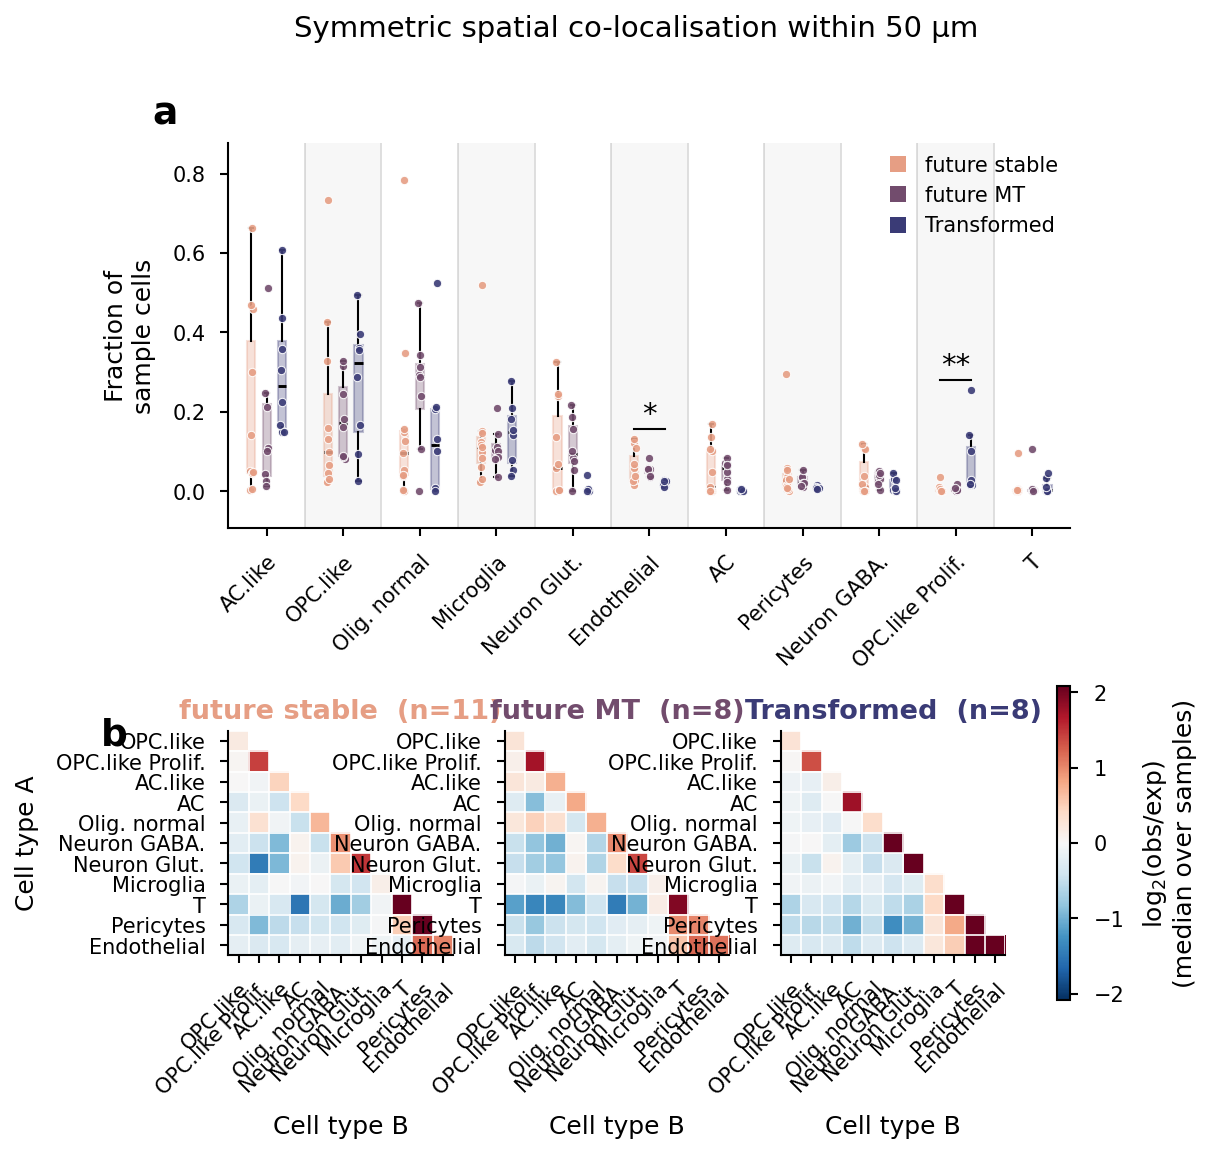

In [11]:
GROUP_ORDER  = ["future stable", "future MT",'Transformed']

GROUP_COLORS = {'future MT': '#724C6D', 'future stable': '#E69E84','Transformed' : '#3A3B76'}

#GROUP_SHORT  = {"future stable | Init": "stable/Init", "future MT": "MT"}  # optional short labels

fig, stats = plot_coloc_panel(
    coloc_df,                 # output of compute_coloc (must have log2OE, nA, typeA/typeB, sample_group, sample)
    GROUP_COLORS, GROUP_ORDER, celltypes,
    out_dir=f"{OUT_DIR}fig1_coloc_panel.pdf",
    celltype_order=celltypes,   # heatmap ordering (fraction panel self-sorts by abundance)
    radius=RADIUS,
   # group_short=GROUP_SHORT,
    min_valid=3,                     # min samples per group to run a test
    alpha=0.05,                      # FDR threshold for stars / panel c
    ab_layout="stacked",
    fig_width_mm = 92,
    frac_spread=0.4,
)

In [12]:
prolif_stats = stats.loc[stats['feature'].isin(['OPC.like Prolif.']),['group','mean','sd','q_value']].set_index('group')
print(f"fraction of OPC.like Prolif. stable: {np.round(prolif_stats.loc['future stable','mean'],3)*100} ({np.round(prolif_stats.loc['future stable','sd'],3)*100})") 
print(f"fraction of OPC.like Prolif. MT: {np.round(prolif_stats.loc['future MT','mean'],3)*100} ({np.round(prolif_stats.loc['future MT','sd'],3)*100})") 
print(f"fraction of OPC.like Prolif. Transformed: {np.round(prolif_stats.loc['Transformed','mean'],3)*100} ({np.round(prolif_stats.loc['Transformed','sd'],3)*100})")
print(f"BH corrected pvalue {prolif_stats.loc['Transformed','q_value']}")

fraction of OPC.like Prolif. stable: 0.5 (1.0999999999999999)
fraction of OPC.like Prolif. MT: 0.5 (0.6)
fraction of OPC.like Prolif. Transformed: 7.3999999999999995 (8.799999999999999)
BH corrected pvalue 0.00893380222583351


In [13]:
endo_stats = stats.loc[stats['feature'].isin(['Endothelial']),['group','mean','sd','q_value']].set_index('group')
print(f"fraction of Endothelial stable: {np.round(endo_stats.loc['future stable','mean'],3)*100} ({np.round(endo_stats.loc['future stable','sd'],3)*100})") 
print(f"fraction of Endothelial MT: {np.round(endo_stats.loc['future MT','mean'],3)*100} ({np.round(endo_stats.loc['future MT','sd'],3)*100})") 
print(f"fraction of Endothelial Transformed: {np.round(endo_stats.loc['Transformed','mean'],3)*100} ({np.round(endo_stats.loc['Transformed','sd'],3)*100})")
print(f"BH corrected pvalue {endo_stats.loc['Transformed','q_value']}")

fraction of Endothelial stable: 6.1 (4.2)
fraction of Endothelial MT: 5.4 (1.5)
fraction of Endothelial Transformed: 2.0 (0.7000000000000001)
BH corrected pvalue 0.023389240255954808


In [14]:
T_E_stats = stats.loc[stats['feature'].isin(['T — Endothelial']),['group','mean','sd','q_value']].set_index('group')
M_E_stats = stats.loc[stats['feature'].isin(['Microglia — Endothelial']),['group','mean','sd','q_value']].set_index('group')
M_T_stats = stats.loc[stats['feature'].isin(['Microglia — T']),['group','mean','sd','q_value']].set_index('group')

T_E = np.round(T_E_stats.loc['Transformed','mean'],2) - np.round(T_E_stats.loc['future stable','mean'],2)
M_E = np.round(M_E_stats.loc['Transformed','mean'],2) - np.round(M_E_stats.loc['future stable','mean'],2)
T_M = np.round(M_T_stats.loc['Transformed','mean'],2) - np.round(M_T_stats.loc['future stable','mean'],2)
print(f"Change in T - endo: {2**(T_E)})") 
print(f"Change in Micro - endo: {2**(M_E)})") 
print(f"Change in T - Micro: {2**(T_M)})") 

print(f"T - endo BH corrected pvalue {T_E_stats.loc['Transformed','q_value']}")
print(f"Micro - endo BH corrected pvalue {M_E_stats.loc['Transformed','q_value']}")
print(f"T - Micro BH corrected pvalue {M_T_stats.loc['Transformed','q_value']}")

Change in T - endo: 1.4240501955970717)
Change in Micro - endo: 2.070529847682755)
Change in T - Micro: 1.3947436663504054)
T - endo BH corrected pvalue 0.8834359488140642
Micro - endo BH corrected pvalue 0.3872863646403058
T - Micro BH corrected pvalue 0.46240416953606506


In [15]:
OP_O_stats = stats.loc[stats['feature'].isin(['OPC.like — Olig. normal']),['group','mean','sd','q_value']].set_index('group')
print(f"log2FC of Olig norm - OPC like stable: {np.round(OP_O_stats.loc['future stable','mean'],2)} ({np.round(OP_O_stats.loc['future stable','sd'],2)})") 
print(f"log2FC of Olig norm - OPC like MT: {np.round(OP_O_stats.loc['future MT','mean'],2)} ({np.round(OP_O_stats.loc['future MT','sd'],2)})") 
print(f"log2FC of Olig norm - OPC like Transformed: {np.round(OP_O_stats.loc['Transformed','mean'],2)} ({np.round(OP_O_stats.loc['Transformed','sd'],2)})")
print(f"BH corrected pvalue {OP_O_stats.loc['Transformed','q_value']}")

log2FC of Olig norm - OPC like stable: -0.2 (0.35)
log2FC of Olig norm - OPC like MT: 0.23 (0.28)
log2FC of Olig norm - OPC like Transformed: -0.12 (0.14)
BH corrected pvalue 0.3250193205461366


In [16]:
 stats['feature'].unique()

array(['AC.like', 'OPC.like', 'Olig. normal', 'Microglia', 'Neuron Glut.',
       'Endothelial', 'AC', 'Pericytes', 'Neuron GABA.',
       'OPC.like Prolif.', 'T', 'OPC.like — OPC.like',
       'OPC.like — OPC.like Prolif.', 'OPC.like — AC.like',
       'OPC.like — AC', 'OPC.like — Olig. normal',
       'OPC.like — Neuron GABA.', 'OPC.like — Neuron Glut.',
       'OPC.like — Microglia', 'OPC.like — T', 'OPC.like — Pericytes',
       'OPC.like — Endothelial', 'OPC.like Prolif. — OPC.like Prolif.',
       'OPC.like Prolif. — AC.like', 'OPC.like Prolif. — AC',
       'OPC.like Prolif. — Olig. normal',
       'OPC.like Prolif. — Neuron GABA.',
       'OPC.like Prolif. — Neuron Glut.', 'OPC.like Prolif. — Microglia',
       'OPC.like Prolif. — T', 'OPC.like Prolif. — Pericytes',
       'OPC.like Prolif. — Endothelial', 'AC.like — AC.like',
       'AC.like — AC', 'AC.like — Olig. normal', 'AC.like — Neuron GABA.',
       'AC.like — Neuron Glut.', 'AC.like — Microglia', 'AC.like — T',
       